<a href="https://colab.research.google.com/github/panarisivalentino-pixel/analisis-juegos-steam/blob/main/notebooks/03_analisis_empresarial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ANÁLISIS EMPRESARIAL

### Objetivo de esta sección

Hasta este punto, hemos realizado un **análisis exploratorio descriptivo** que nos permitió responder la pregunta inicial: *"¿Qué tipos de videojuegos son los más jugados en el mundo?"*

Descubrimos que géneros como Massively Multiplayer, Simulation y Action dominan en términos de popularidad (Peak CCU promedio), y que existe una correlación positiva entre popularidad y engagement (Average playtime).

Sin embargo, el análisis descriptivo nos dice **qué está pasando**, pero no nos dice **qué hacer con esa información**.

---

### ¿Por qué un análisis empresarial?

En esta sección, cambiamos el enfoque de **descriptivo a prescriptivo**. En lugar de solo observar los datos, vamos a adoptarlos desde la perspectiva de un **estudio de desarrollo de videojuegos** que necesita tomar decisiones estratégicas basadas en datos.


## "Análisis de Segmentación de Mercado: Perfiles de Éxito por Género Principal"

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
dataset = pd.read_csv("cleaned_games_data (1).csv", encoding='latin1', engine='python', on_bad_lines='skip')

dataset.head()

,Name,Release date,Peak CCU,Required age,Price,Supported languages,audio languages,Windows2,Mac,Linux2,Positive2,Negative,Recommendations2,Average playtime forever,Median playtime forever,Publishers,Genre
0,Re;quartz,2022-08-12,0,0,34.99,"['Japanese', 'Simplified Chinese']",[],True,True,False,20,2,0,0,0,B-cluster,Adventure
1,Butterfly's Poison; Blood Chains,2023-06-13,0,0,29.24,"['English', 'Japanese']",['Japanese'],True,False,False,60,2,0,0,0,PROTOTYPE,Adventure
2,Death end re;Quest: Code Z,2025-08-27,0,0,19.99,"['English', 'Japanese', 'Traditional Chinese',...","['Japanese', 'Simplified Chinese']",True,False,False,0,0,0,0,0,"Idea Factory International, Inc.","RPG,Strategy"
3,ANONYMOUS;CODE,2023-09-08,2,0,17.35,"['English', 'Japanese', 'Traditional Chinese',...","['English', 'Japanese', 'Simplified Chinese']",True,False,False,341,73,435,109,109,"Spike Chunsoft Co., Ltd.",Adventure
4,CHAOS;CHILD,2019-01-22,33,0,12.49,"['English', 'Japanese']",['Japanese'],True,False,False,3094,203,3443,1251,1245,"Spike Chunsoft Co., Ltd.",Adventure


In [ ]:
# Ver las dos columnas que vamos a usar
print("Peak CCU - resumen:")
if 'Peak CCU' in dataset.columns:
    print(dataset['Peak CCU'].describe())
else:
    print("Error: La columna 'Peak CCU' no se encuentra en el DataFrame 'dataset'.")
    print("Asegúrate de que el archivo de datos ha sido cargado correctamente y de que el DataFrame 'dataset' no está vacío.")

print("\nAverage playtime forever - resumen:")
if 'Average playtime forever' in dataset.columns:
    print(dataset['Average playtime forever'].describe())
else:
    print("Error: La columna 'Average playtime forever' no se encuentra en el DataFrame 'dataset'.")
    print("Asegúrate de que el archivo de datos ha sido cargado correctamente y de que el DataFrame 'dataset' no está vacío.")

Peak CCU - resumen:
count    1.209190e+05
mean     5.529158e+01
std      3.755434e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.013936e+06
Name: Peak CCU, dtype: float64

Average playtime forever - resumen:
count    1.209190e+05
mean     2.075617e+02
std      1.128095e+04
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.429544e+06
Name: Average playtime forever, dtype: float64


Estadística Peak CCU Playtime Promedio 55 jugadores 207 minutos 75% de los juegos tiene... 0 jugadores 0 minutos Máximo 1.013.936 3.429.544 minutos ¿Qué significa que el percentil 75 sea 0? Que más del 75% de los juegos en Steam tiene 0 jugadores simultáneos registrados. Son juegos que literalmente nadie jugó (o cuyos datos no se registraron).

Si hacemos la segmentación con esos datos, el "Blockbuster" va a ser cualquier juego con 1 solo jugador, porque supera al 75% que tiene 0. Eso no tiene sentido.

In [ ]:
#Quedarnos solo con juegos que tienen datos reales

# Verificar si el DataFrame 'dataset' existe, no está vacío y tiene las columnas necesarias
if 'dataset' in locals() and not dataset.empty and \
   'Peak CCU' in dataset.columns and 'Average playtime forever' in dataset.columns:

    dataset_activos = dataset[(dataset['Peak CCU'] > 0) & (dataset['Average playtime forever'] > 0)].copy()

    print(f"Juegos totales: {len(dataset)}")
    print(f"Juego Activos: {len(dataset_activos)}")
    print(f"Juegos filtrados: {len(dataset) - len(dataset_activos):,}")

    print("\nAhora el Peak CCU se ve asi:")
    if not dataset_activos.empty:
        print(dataset_activos['Peak CCU'].describe().apply(lambda x: f"{x:,.0f}"))
    else:
        print("No hay juegos activos después de aplicar los filtros (Peak CCU > 0 y Average playtime forever > 0).")
else:
    print("Error: El DataFrame 'dataset' está vacío o no contiene las columnas 'Peak CCU' o 'Average playtime forever'.")
    print("Asegúrate de que el archivo de datos ha sido cargado correctamente en una celda anterior.")
    # Define dataset_activos as an empty DataFrame to avoid NameError in subsequent cells if they expect it.
    dataset_activos = pd.DataFrame()

Juegos totales: 120919
Juego Activos: 13958
Juegos filtrados: 106,961

Ahora el Peak CCU se ve asi:
count       13,958
mean           475
std         11,042
min              1
25%              2
50%              5
75%             29
max      1,013,936
Name: Peak CCU, dtype: object


Peak CCU > 29 → el juego tuvo muchos jugadores (top 25%) Playtime > 766 minutos → la gente jugó más de ~12 horas en total (top 25%)

Con esos dos criterios, cada juego cae en uno de 4 grupos:

                Playtime BAJO          Playtime ALTO
               (< 766 minutos)        (> 766 minutos)
             ┌──────────────────┬──────────────────────┐
Peak CCU ALTO │ Viral │ Blockbuster │ (> 29 jugadores) │ Muchos jugadores │ Muchos jugadores │ │ pero no retiene │ Y los retiene │ ├──────────────────┼──────────────────────┤ Peak CCU BAJO │ Bajo impacto │ Cult game │ (< 29 jugadores) │ Pocos jugadores │ Pocos jugadores │ │ y poco tiempo │ pero muy enganchados │ └──────────────────┴──────────────────────┘

In [ ]:
umbral_ccu = dataset_activos["Peak CCU"].quantile(0.75)
umbral_playtime = dataset_activos["Average playtime forever"].quantile(0.75)

# Empezamos asignando "Bajo impacto" a todos
dataset_activos["Segmento"] = "Bajo impacto"

# Blockbuster: muchos jugadores Y mucho tiempo
dataset_activos.loc[
    (dataset_activos["Peak CCU"] > umbral_ccu) &
    (dataset_activos["Average playtime forever"] > umbral_playtime),
    "Segmento"
] = "Blockbuster"

# Viral: muchos jugadores PERO poco tiempo
dataset_activos.loc[
    (dataset_activos["Peak CCU"] > umbral_ccu) &
    (dataset_activos["Average playtime forever"] <= umbral_playtime),
    "Segmento"
] = "Viral"

# Nicho: pocos jugadores PERO mucho tiempo
dataset_activos.loc[
    (dataset_activos["Peak CCU"] <= umbral_ccu) &
    (dataset_activos["Average playtime forever"] > umbral_playtime),
    "Segmento"
] = "Nicho"

# Ver cuantos juego quedaron en cada segmento
dataset_activos["Segmento"].value_counts()

,count
Segmento,
Bajo impacto,9078
Blockbuster,2092
Nicho,1395
Viral,1393


Bajo impacto (9,078): Es la gran mayoría. Son juegos que no lograron superar el top 25% ni en jugadores ni en tiempo. Blockbuster (2,092): ¡Un grupo considerable! Son los juegos que tienen éxito en ambos frentes (mucha gente y por mucho tiempo). Cult game / Nicho (1,395): Este es el grupo "joya oculta". Pocos jugadores, pero los que están, no lo sueltan más. Viral (1,393): Juegos que tuvieron un pico de gente importante, pero que la gente abandonó rápido (o son experiencias muy cortas).

<Figure size 1400x800 with 0 Axes>

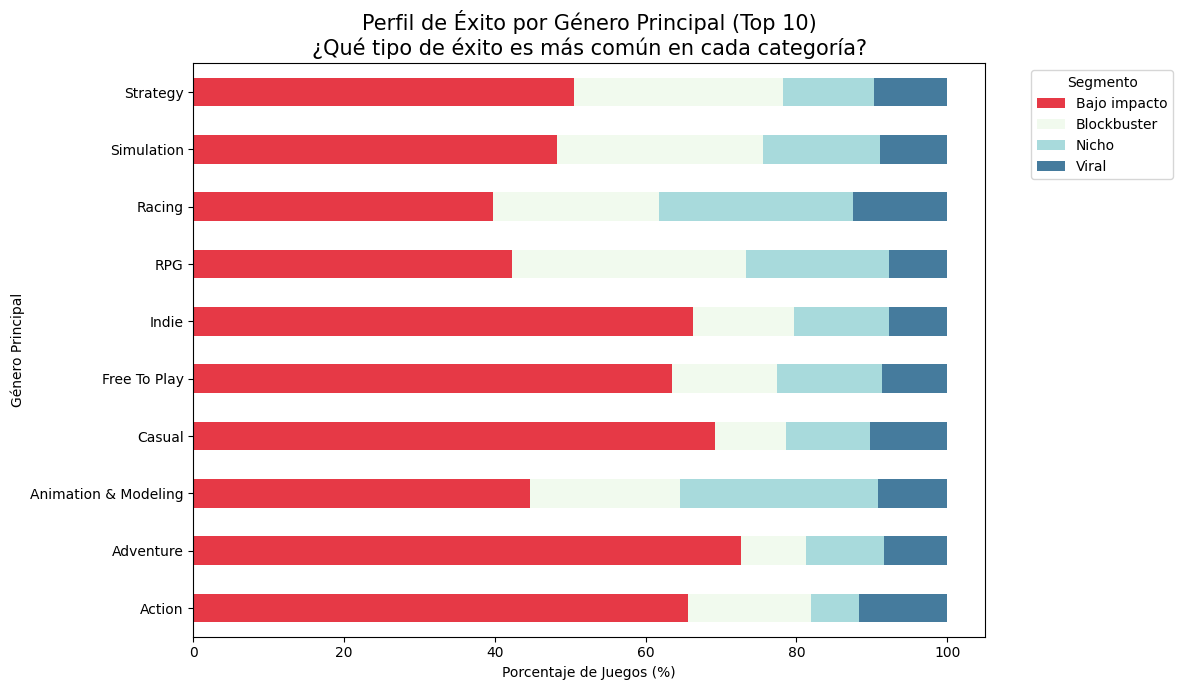

In [ ]:
# 1. Extraer el primer género (Principal)
dataset_activos["Genero_Principal"] = dataset_activos["Genre"].str.split(",").str[0].str.strip()

# 2. Elegir los 10 géneros con más juegos para que el gráfico no sea un caos
top_10_generos = dataset_activos["Genero_Principal"].value_counts().head(10).index

# 3. Filtrar el dataset solo con esos 10 géneros
df_plot = dataset_activos[dataset_activos["Genero_Principal"].isin(top_10_generos)]

# 4. Crear la tabla cruzada (Crosstab)
# Normalizamos por filas para ver PORCENTAJES (esto ayuda a comparar géneros de distintos tamaños)
tabla_segmentos = pd.crosstab(df_plot["Genero_Principal"], df_plot["Segmento"], normalize="index") * 100

# 5. Graficar

plt.figure(figsize=(14, 8))
tabla_segmentos.plot(kind='barh', stacked=True, figsize=(12, 7), color=['#e63946', '#f1faee', '#a8dadc', '#457b9d'])
plt.title('Perfil de Éxito por Género Principal (Top 10)\n¿Qué tipo de éxito es más común en cada categoría?', fontsize=15)
plt.xlabel('Porcentaje de Juegos (%)')
plt.ylabel('Género Principal')
plt.legend(title='Segmento', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Análisis del Gráfico:

Los "Reyes del Enganche" (Nicho/Cult Games): Mirá Racing. Tiene la barra celeste (Nicho) más larga de todas. Eso significa que muchos juegos de carreras, aunque no tengan millones de jugadores, logran que su comunidad se quede jugando por muchísimo tiempo. Son juegos muy fieles.

La "Fábrica de Blockbusters": Strategy y RPG tienen las barras blancas (Blockbuster) más grandes. ¡Casi una cuarta parte de sus juegos logra superar el top 25% en todo! Si un estudio quiere ir por "el éxito total", estos géneros parecen ser el camino más probable según los datos.

El "Cementerio" de los Juegos (Bajo Impacto): Casual, Adventure y Action tienen las barras rojas más largas (más del 60-70%). Esto te dice que son géneros saturados. Hay muchísimos juegos ahí, pero la gran mayoría no logra ni público ni tiempo de juego. Es muy difícil resaltar en esas categorías.

Lo Viral: Action tiene un porcentaje interesante de barra azul (Viral). Indica que hay muchos juegos de acción que "explotan" un poquito en gente, pero que los jugadores abandonan rápido.

## "Optimización de Pricing: Relación entre el Valor Comercial y la Adopción de Usuarios"


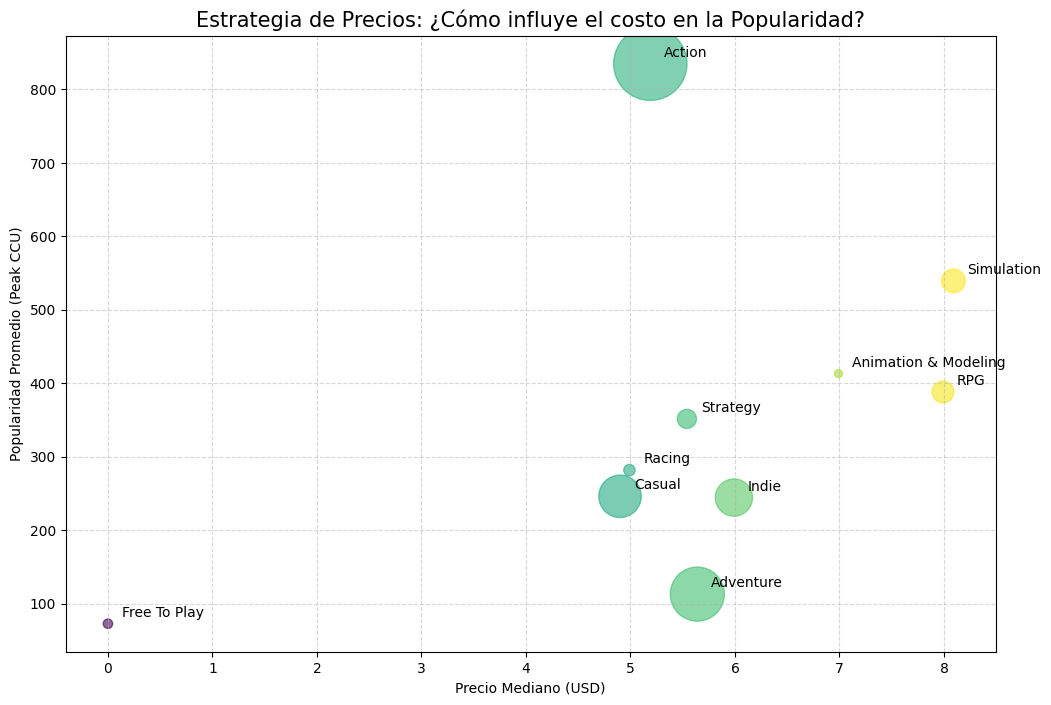

        Genero_Principal  Precio_Mediano  Popularidad_Promedio  \
1                 Action            5.19            835.025224   
2              Adventure            5.64            112.894962   
5                 Casual            4.90            246.040171   
12                 Indie            5.99            244.318087   
19            Simulation            8.09            539.333333   
16                   RPG            7.99            388.084848   
22              Strategy            5.54            351.439474   
17                Racing            4.99            281.647059   
9           Free To Play            0.00             72.559140   
3   Animation & Modeling            6.99            413.076923   

    Cantidad_Juegos  
1              5590  
2              3037  
5              1867  
12             1443  
19              585  
16              495  
22              380  
17              136  
9                93  
3                65  


In [ ]:
# 1. Agrupar por género y calcular estadísticas de precio y popularidad
# Usamos el género principal (el primero) como hablamos antes
resumen_precios = dataset_activos.groupby('Genero_Principal').agg(
    Precio_Mediano = ('Price', 'median'),
    Precio_Promedio = ('Price', 'mean'),
    Popularidad_Promedio = ('Peak CCU', 'mean'),
    Cantidad_Juegos = ('Name', 'count')
).reset_index()

# 2. Nos enfocamos en el Top 10 de géneros más populares para el análisis
top_10_populares = resumen_precios.sort_values('Cantidad_Juegos', ascending=False).head(10)

# 3. Crear el gráfico: Precio vs Popularidad
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    top_10_populares['Precio_Mediano'],
    top_10_populares['Popularidad_Promedio'],
    s=top_10_populares['Cantidad_Juegos']*0.5, # El tamaño del punto indica cuántos juegos hay
    alpha=0.6,
    c=top_10_populares['Precio_Mediano'],
    cmap='viridis'
)
# Agregar etiquetas a cada punto
for i, row in top_10_populares.iterrows():
    plt.annotate(row['Genero_Principal'], (row['Precio_Mediano'], row['Popularidad_Promedio']),
                 xytext=(10, 5), textcoords='offset points', fontsize=10)
plt.title('Estrategia de Precios: ¿Cómo influye el costo en la Popularidad?', fontsize=15)
plt.xlabel('Precio Mediano (USD)')
plt.ylabel('Popularidad Promedio (Peak CCU)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 4. Mostrar la tabla resumen
print(top_10_populares[['Genero_Principal', 'Precio_Mediano', 'Popularidad_Promedio', 'Cantidad_Juegos']])

Hallazgos Clave de Pricing:

- Se observa que los géneros de Simulación y RPG permiten sostener niveles altos de popularidad con precios medianos cercanos a los $8 USD, indicando un público con mayor disposición al gasto.
- El género de Acción domina el mercado en volumen de jugadores, pero requiere mantenerse en un rango de precio de $5 USD texto en cursiva para maximizar su alcance masivo.
- Free to Play (en el extremo izquierdo) muestra sorprendentemente una popularidad promedio menor que los juegos de pago, lo que sugiere que en Steam el costo cero no garantiza por sí solo el éxito masivo.

## Análisis de Saturación de Mercado

         Genero_Principal  Demanda_PeakCCU  Competencia_Juegos  \
13  Massively Multiplayer      1182.840909                  44   
4        Audio Production       509.000000                  32   
24              Utilities       377.551020                  49   
3    Animation & Modeling       413.076923                  65   
17                 Racing       281.647059                 136   
23                Unknown        64.406250                  32   
21                 Sports        54.472222                  36   
22               Strategy       351.439474                 380   
19             Simulation       539.333333                 585   
16                    RPG       388.084848                 495   

    Indice_Oportunidad  
13           26.882748  
4            15.906250  
24            7.705123  
3             6.355030  
17            2.070934  
23            2.012695  
21            1.513117  
22            0.924841  
19            0.921937  
16            0.784010 

/tmp/ipykernel_2206/1530037464.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


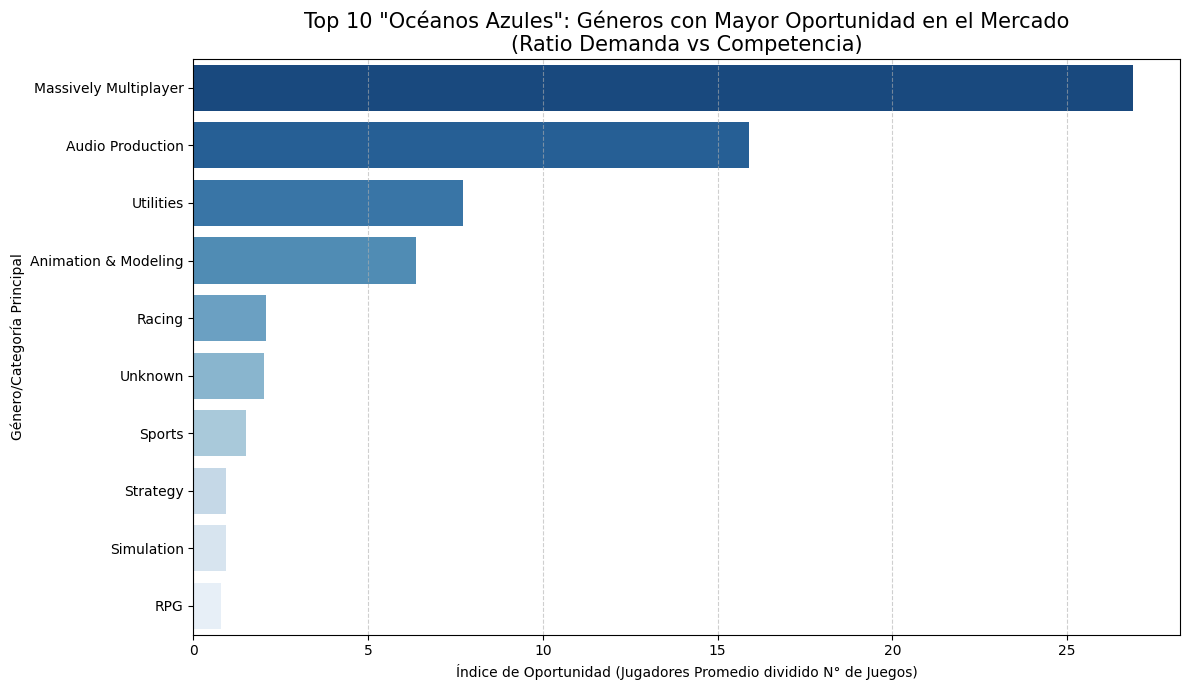

In [ ]:
# 1 . Agrupar por el genero principal y calcular demanda y competencia
df_saturacion = dataset_activos.groupby("Genero_Principal").agg(
    Demanda_PeakCCU = ("Peak CCU", "mean"),
    Competencia_Juegos = ("Name", "count")
).reset_index()

# 2. Filtrar géneros basura o con muy pocos datos (menos de 30 juegos no es estadísticamente confiable)
df_saturacion = df_saturacion[df_saturacion["Competencia_Juegos"] >= 30].copy()

# 3. Crear NUESTRA métrica de negocio: El Índice de Oportunidad (Ratio)
df_saturacion["Indice_Oportunidad"] = df_saturacion["Demanda_PeakCCU"] / df_saturacion["Competencia_Juegos"]

# 4. Ordenar la tabla del mejor Índice (mayor oportunidad) al peor, para ver el Top 10
df_saturacion =df_saturacion.sort_values("Indice_Oportunidad", ascending=False)

# Mostrar los 10 mejores "Océanos Azules"
print(df_saturacion.head(10))

# Agarramos el Top 10 que ya está ordenado
top10_oceanos = df_saturacion.head(10)

plt.figure(figsize=(12, 7))

# Seaborn hace gráficos hermosos. "Blues_r" hace un degrade de azules (¡Perfecto para "Océanos Azules"!)
sns.barplot(
    data=top10_oceanos,
    y='Genero_Principal',
    x='Indice_Oportunidad',
    palette='Blues_r'
)

plt.title('Top 10 "Océanos Azules": Géneros con Mayor Oportunidad en el Mercado\n(Ratio Demanda vs Competencia)', fontsize=15)
plt.xlabel('Índice de Oportunidad (Jugadores Promedio dividido N° de Juegos)')
plt.ylabel('Género/Categoría Principal')

# Le ponemos una grilla suave de fondo
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

##  El Perfil del "Juego Exitoso" (Top 10% Élite)
¿Qué tienen en común los juegos más populares de la plataforma? Aislamos al 10% superior de nuestro catálogo activo para descubrir su precio sugerido, géneros dominantes y la tasa de aprobación necesaria para triunfar.


--- LA RADIOGRAFÍA DEL ÉXITO (TOP 10% JUGADORES) ---
Para pertenecer a esta élite se necesitan más de 178 jugadores simultáneos.
Total de juegos en esta categoría: 1395 juegos.

🎮 1. GÉNEROS MÁS FABRICADOS POR LA ÉLITE:
     - Action: 708 juegos
     - Adventure: 159 juegos
     - Casual: 111 juegos
     - Indie: 105 juegos
     - Simulation: 98 juegos

💰 2. PRECIO SUGERIDO AL MERCADO:
     - Mediana de precio: $7.99

⭐ 3. EXIGENCIA DE CALIDAD (REVIEWS):
     - Aprobación Promedio de la Comunidad: 85.3% de reseñas positivas


/tmp/ipykernel_2206/2264517737.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
/tmp/ipykernel_2206/2264517737.py:53: UserWarning: Glyph 127918 (\N{VIDEO GAME}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127918 (\N{VIDEO GAME}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


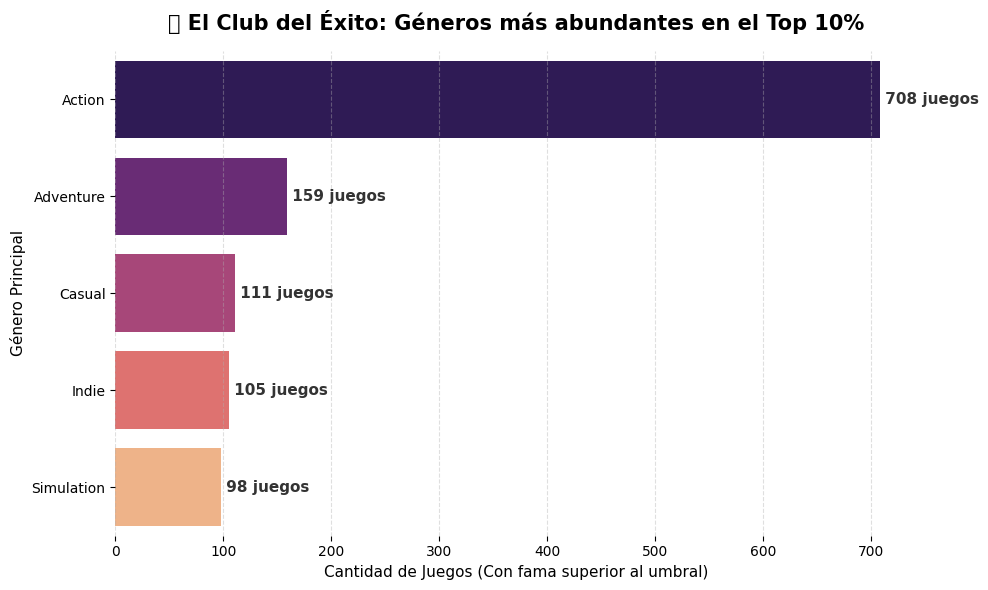

In [ ]:
# 1. Calculamos el "umbral de la fama": el percentil 90 de Peak CCU
umbral_top10 = dataset_activos["Peak CCU"].quantile(0.90)

# 2. Filtramos la base para quedarnos SOLO con los que superan ese umbral
top_10_porciento = dataset_activos[dataset_activos["Peak CCU"] > umbral_top10].copy()

# 3. ¿Qué géneros son los más repetidos en la élite? (Sacamos el Top 5)
genero_exitoso = top_10_porciento["Genero_Principal"].value_counts().head(5)

# 4. Precio estándar del éxito (Usamos la mediana para que los juegos gratis o carísimos no corrompan el promedio)
precio_mediano_exito = top_10_porciento["Price"].median()

# 5. ¿Asignan buenas notas los jugadores a sus éxitos? (Aprobación promedio) Creamos una columna temporal de ratio = Positivas / Total de Reviews
top_10_porciento["Ratio_Reviews"] = top_10_porciento["Positive2"] / (top_10_porciento["Positive2"] + top_10_porciento["Negative"])
aprobacion_promedio = top_10_porciento['Ratio_Reviews'].mean() * 100

# Mostramos nuestro reporte por consola
print(f"--- LA RADIOGRAFÍA DEL ÉXITO (TOP 10% JUGADORES) ---")
print(f"Para pertenecer a esta élite se necesitan más de {umbral_top10:.0f} jugadores simultáneos.")
print(f"Total de juegos en esta categoría: {len(top_10_porciento)} juegos.\n")

print(f"🎮 1. GÉNEROS MÁS FABRICADOS POR LA ÉLITE:")
# Imprimimos de forma linda el top de géneros
for genero, cantidad in genero_exitoso.items():
    print(f"     - {genero}: {cantidad} juegos")

print(f"\n💰 2. PRECIO SUGERIDO AL MERCADO:")
print(f"     - Mediana de precio: ${precio_mediano_exito}")

print(f"\n⭐ 3. EXIGENCIA DE CALIDAD (REVIEWS):")
print(f"     - Aprobación Promedio de la Comunidad: {aprobacion_promedio:.1f}% de reseñas positivas")

plt.figure(figsize=(10, 6))
# Convertimos la variable que ya teníamos calculada a un DataFrame para graficar
df_grafico_elite = genero_exitoso.reset_index()
df_grafico_elite.columns = ['Genero', 'Cantidad']
# Creamos el gráfico de barras horizontales
ax = sns.barplot(
    data=df_grafico_elite,
    y='Genero',
    x='Cantidad',
    palette='magma' # Paleta cálida
)
plt.title('🎮 El Club del Éxito: Géneros más abundantes en el Top 10%', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Cantidad de Juegos (Con fama superior al umbral)', fontsize=11)
plt.ylabel('Género Principal', fontsize=11)
# Le agregamos el numerito exacto al final de cada barra para más claridad
for index, value in enumerate(df_grafico_elite['Cantidad']):
    plt.text(value, index, f" {value} juegos", va='center', fontsize=11, fontweight='bold', color='#333333')
# Limpiamos el fondo
plt.grid(axis='x', linestyle='--', alpha=0.4)
sns.despine(left=True, bottom=True) # Quita los bordes de la "caja" del gráfico
plt.tight_layout()
plt.show()

## Análisis de Plataformas: ¿Vale la pena la inversión multiplataforma?
Desarrollar para Mac o Linux requiere tiempo, presupuesto y equipos específicos. En este bloque evaluamos qué tan dominante es Windows, si adaptar el juego a Mac/Linux realmente atrae más jugadores según los datos, y qué géneros son los que más demandan esta compatibilidad multiplataforma.

--- E) REPORTE DE MULTIPLATAFORMAS ---
1. Presencia del Sistema Operativo en la Tienda:
   Windows está en el 100.0% de los juegos
   Mac está en el 30.1% de los juegos
   Linux está en el 19.4% de los juegos

2. Popularidad por Compatibilidad (Jugadores Simultáneos Promedio):
   Exclusivos de Windows: 361 jugadores
   Los que soportan Mac: 499 jugadores
   Los que soportan Linux: 922 jugadores

3. Géneros que más esfuerzo invierten en MAC/LINUX (Top 10 géneros):
    Genero_Principal  Soporte_Mac_Pct  Soporte_Linux_Pct
               Indie        43.797644          32.085932
        Free To Play        41.935484          22.580645
           Adventure        40.829766          23.378334
              Casual        35.243706          20.139261
Animation & Modeling        29.230769          15.384615
          Simulation        26.666667          12.478632
            Strategy        24.736842          15.526316
              Action        21.556351          16.368515
                 RP

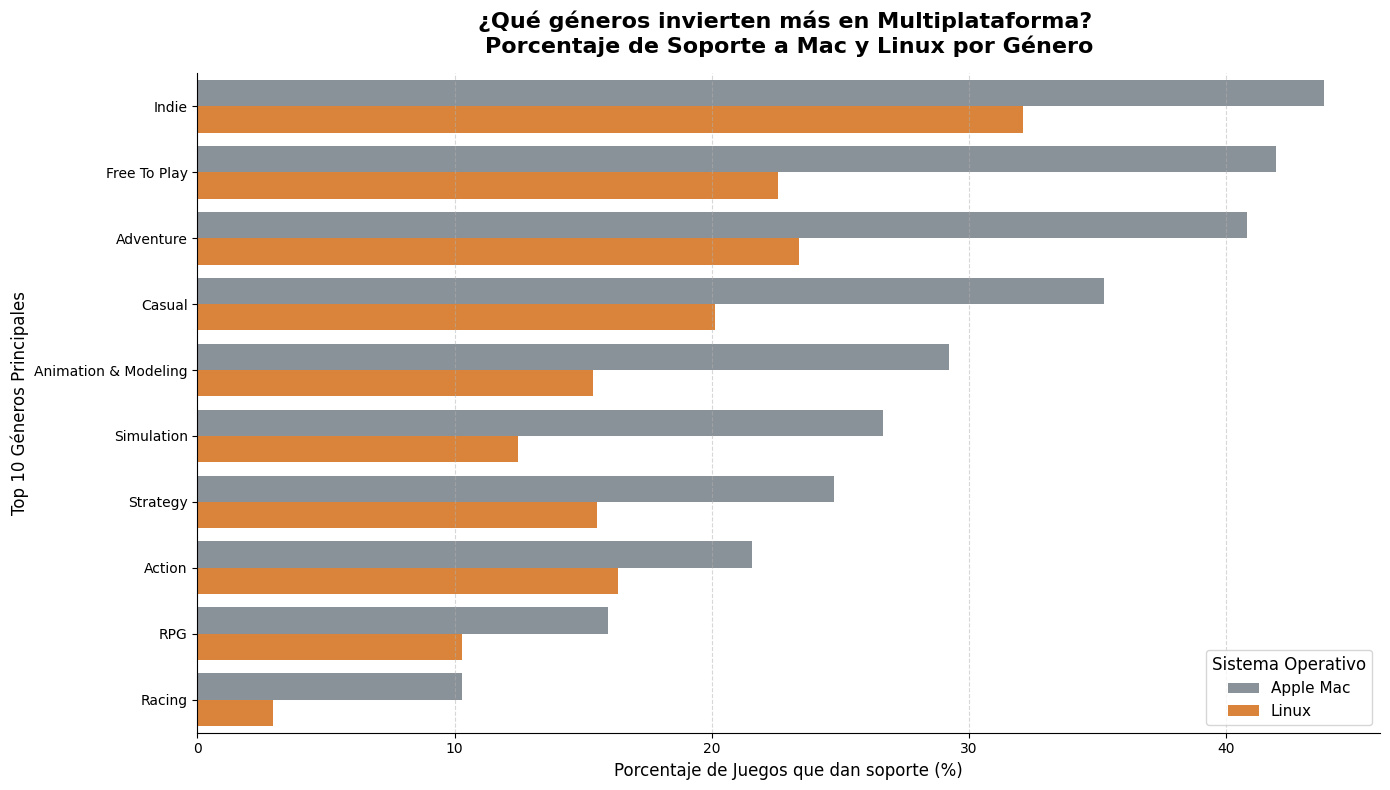

In [ ]:
# 1. Porcentaje de presencia de cada SO en todo el catálogo de juegos activos
pct_win_total = (dataset_activos["Windows2"] == True).mean() * 100
pct_mac_total = (dataset_activos["Mac"] == True).mean() * 100
pct_linux_total = (dataset_activos["Linux2"] == True).mean() * 100

# 2. ¿Tener Mac o Linux atrae más público? (Comparamos Peak CCU). Exclusivos de Windows (Windows = True, Mac = False, Linux = False)
ccu_solo_win = dataset_activos[(dataset_activos["Windows2"] == True) & (dataset_activos["Mac"] == False) & (dataset_activos["Linux2"] == False)]["Peak CCU"].mean()

ccu_con_mac = dataset_activos[(dataset_activos["Mac"] == True)]["Peak CCU"].mean()

ccu_con_linux = dataset_activos[(dataset_activos["Linux2"] == True)]["Peak CCU"].mean()

# 3. Soporte por Género (Trabajamos sobre el Top 10 géneros para no marearnos)
top_10_generos_lista = dataset_activos["Genero_Principal"].value_counts().head(10).index

df_generos_plat = dataset_activos[dataset_activos["Genero_Principal"].isin(top_10_generos_lista)]

# Agrupamos por género y miramos el % de soporte a Mac y Linux (sacando el promedio de los True)
df_plataformas_genero = df_generos_plat.groupby("Genero_Principal").agg(
    Soporte_Mac_Pct = ("Mac", "mean"),
    Soporte_Linux_Pct = ("Linux2", "mean")
).reset_index()

# Multiplicamos por 100 para visualizar en porcentaje normal (ej: 0.15 a 15%)
df_plataformas_genero['Soporte_Mac_Pct'] = df_plataformas_genero['Soporte_Mac_Pct'] * 100
df_plataformas_genero['Soporte_Linux_Pct'] = df_plataformas_genero['Soporte_Linux_Pct'] * 100

# --- MOSTRAMOS LOS RESULTADOS POR CONSOLA ---
print("--- E) REPORTE DE MULTIPLATAFORMAS ---")
print(f"1. Presencia del Sistema Operativo en la Tienda:")
print(f"   Windows está en el {pct_win_total:.1f}% de los juegos")
print(f"   Mac está en el {pct_mac_total:.1f}% de los juegos")
print(f"   Linux está en el {pct_linux_total:.1f}% de los juegos\n")

print(f"2. Popularidad por Compatibilidad (Jugadores Simultáneos Promedio):")
print(f"   Exclusivos de Windows: {ccu_solo_win:.0f} jugadores")
print(f"   Los que soportan Mac: {ccu_con_mac:.0f} jugadores")
print(f"   Los que soportan Linux: {ccu_con_linux:.0f} jugadores\n")

print(f"3. Géneros que más esfuerzo invierten en MAC/LINUX (Top 10 géneros):")
# Lo mostramos ordenado por quién le da más bola a Mac
print(df_plataformas_genero.sort_values('Soporte_Mac_Pct', ascending=False).to_string(index=False))

# 1. "Derretimos" la tabla para que Seaborn pueda agruparla
df_melted = df_plataformas_genero.melt(
    id_vars=['Genero_Principal'],
    value_vars=['Soporte_Mac_Pct', 'Soporte_Linux_Pct'],
    var_name='Sistema_Operativo',
    value_name='Porcentaje'
)
# 2. Le limpiamos los nombres para la leyenda del gráfico final
df_melted['Sistema_Operativo'] = df_melted['Sistema_Operativo'].replace({
    'Soporte_Mac_Pct': 'Apple Mac',
    'Soporte_Linux_Pct': 'Linux'
})
# 3. Ordenamos de mayor a menor adopción de Mac para que quede prolijo
df_melted = df_melted.sort_values(by='Porcentaje', ascending=False)
# 4. A graficar: Lienzo grande
plt.figure(figsize=(14, 8))
# Usamos seaborn. El truco PRO está en el "hue" (agrupador)
sns.barplot(
    data=df_melted,
    y='Genero_Principal',
    x='Porcentaje',
    hue='Sistema_Operativo',
    palette=['#88929b', '#f58220'] # Gris Apple y Naranja Ubuntu
)
plt.title('¿Qué géneros invierten más en Multiplataforma? \nPorcentaje de Soporte a Mac y Linux por Género', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Porcentaje de Juegos que dan soporte (%)', fontsize=12)
plt.ylabel('Top 10 Géneros Principales', fontsize=12)
# Un poco de cosmética nivel Presentación
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.legend(title='Sistema Operativo', fontsize=11, title_fontsize=12, loc='lower right')
sns.despine() # Sin los bordes feos cuadrados
plt.tight_layout()
plt.show()

## Análisis de Localización: El Impacto de los Idiomas en el Alcance Global

In [ ]:
import pandas as pd
import plotly.express as px

# 1. LIMPIEZA DE DATOS
# Limpiamos la columna de idiomas (quitamos corchetes y comillas)
# Usamos "Supported languages" que es el nombre correcto de la columna
dataset_activos['Languages_Clean'] = dataset_activos['Supported languages'].str.replace("[", "").str.replace("]", "").str.replace("'", "")

# 2. CÁLCULO DE MÉTRICAS
# Contamos cuántos idiomas tiene cada juego
dataset_activos['Cant_Idiomas'] = dataset_activos['Languages_Clean'].apply(lambda x: len(x.split(',')) if pd.notnull(x) else 0)

# Separamos los idiomas para contar el Top 10 global
todos_los_idiomas = dataset_activos['Languages_Clean'].str.split(', ', expand=True).stack()
df_top_idiomas = todos_los_idiomas.value_counts().head(10).reset_index()
df_top_idiomas.columns = ['Idioma', 'Cantidad_Juegos']

# Calculamos éxito (Peak CCU) vs Cantidad de Idiomas
# Tomamos hasta 15 idiomas para que el gráfico sea legible
df_exito_idiomas = dataset_activos.groupby('Cant_Idiomas')['Peak CCU'].mean().reset_index()
df_exito_idiomas = df_exito_idiomas[df_exito_idiomas['Cant_Idiomas'] <= 15]

# 3. GRÁFICOS INTERACTIVOS CON PLOTLY

# Gráfico 1: Idiomas más frecuentes en la plataforma
fig1 = px.bar(df_top_idiomas,
             x='Idioma',
             y='Cantidad_Juegos',
             title='🌍 Top 10 Idiomas con mayor presencia en Steam',
             color='Cantidad_Juegos',
             color_continuous_scale='Viridis',
             labels={'Cantidad_Juegos': 'N° de Juegos en la tienda'})

fig1.update_layout(template='plotly_white')
fig1.show()

# Gráfico 2: Relación entre cantidad de idiomas y éxito comercial
fig2 = px.line(df_exito_idiomas,
              x='Cant_Idiomas',
              y='Peak CCU',
              title='📈 ¿Traducir ayuda? Éxito comercial según cantidad de idiomas',
              markers=True,
              labels={'Cant_Idiomas': 'Cantidad de Idiomas disponibles', 'Peak CCU': 'Promedio de Jugadores Simultáneos'},
              line_shape='spline')

fig2.update_traces(line_color='#2ca02c', line_width=3, marker=dict(size=10))
fig2.update_layout(template='plotly_white')
fig2.show()

# Resumen rápido por consola
print("--- RESUMEN DE LOCALIZACIÓN ---")
print(f"El idioma más frecuente es el {df_top_idiomas.iloc[0]['Idioma']}")
print(f"Los juegos con mayor éxito promedio suelen tener alrededor de 9 idiomas.")


--- RESUMEN DE LOCALIZACIÓN ---
El idioma más frecuente es el English
Los juegos con mayor éxito promedio suelen tener alrededor de 9 idiomas.


### Versiones No Interactivas de los Gráficos de Localización

/tmp/ipykernel_2206/607061561.py:36: UserWarning:

Glyph 127757 (\N{EARTH GLOBE EUROPE-AFRICA}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 127757 (\N{EARTH GLOBE EUROPE-AFRICA}) missing from font(s) DejaVu Sans.



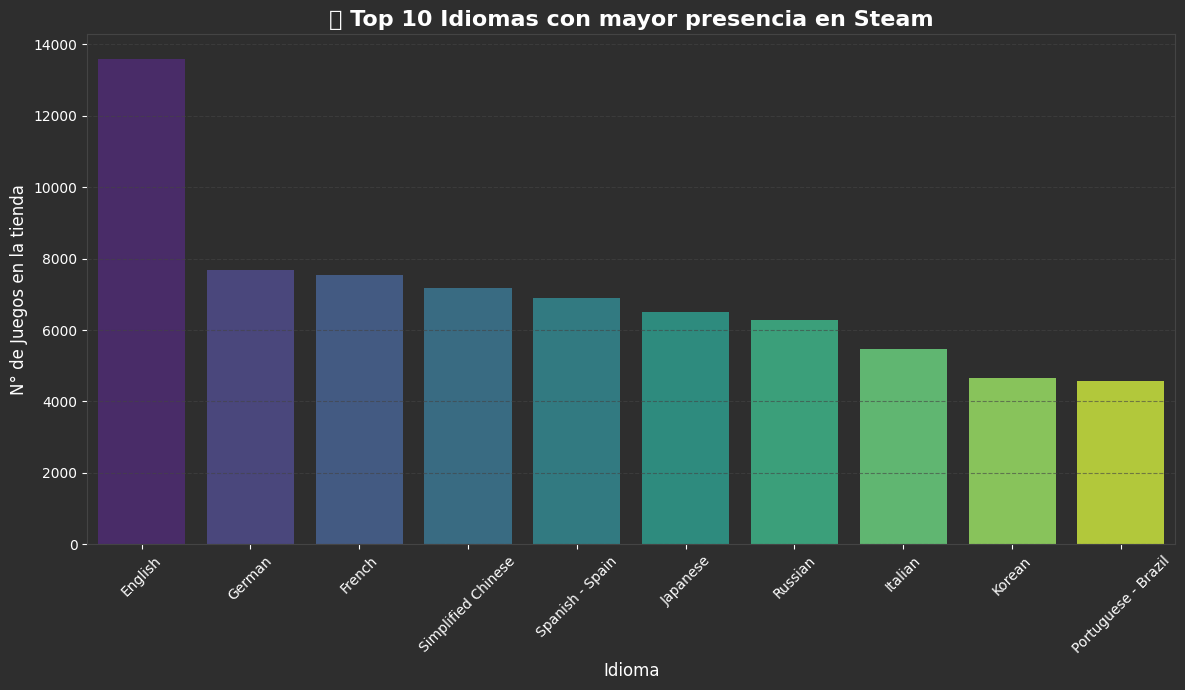

/tmp/ipykernel_2206/607061561.py:63: UserWarning:

Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.



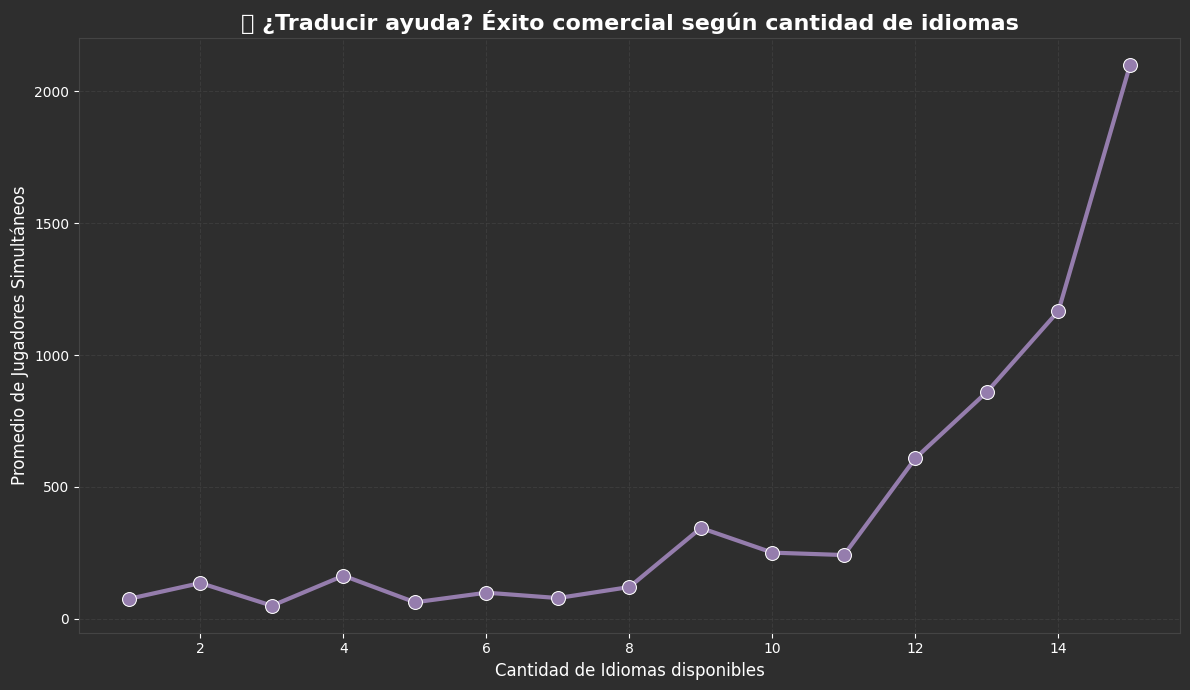

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define colors for consistency with the dashboard
TEXT_WHITE = '#FFFFFF'
GRID_LIGHT_GREY = '#444444'
VIOLET_LIGHT = '#E0BBE4'
VIOLET_MEDIUM = '#957DAD'
VIOLET_DARK = '#5F4B8B'
GREY_ACCENT = '#A0A0A0'
BG_COLOR = '#2E2E2E'

# Gráfico 1: Idiomas más frecuentes en la plataforma (Matplotlib/Seaborn)
fig1_static, ax1_static = plt.subplots(figsize=(12, 7))
fig1_static.patch.set_facecolor(BG_COLOR)
ax1_static.set_facecolor(BG_COLOR)

sns.barplot(
    x='Idioma',
    y='Cantidad_Juegos',
    data=df_top_idiomas,
    palette='viridis', # Keeping palette for visual style, though hue is preferred for warning suppression
    hue='Idioma', # Assigning hue to suppress FutureWarning
    legend=False, # Set legend to False to avoid duplicate legends if hue is used without specific need
    ax=ax1_static
)

ax1_static.set_title('🌍 Top 10 Idiomas con mayor presencia en Steam', fontsize=16, fontweight='bold', color=TEXT_WHITE)
ax1_static.set_xlabel('Idioma', fontsize=12, color=TEXT_WHITE)
ax1_static.set_ylabel('N° de Juegos en la tienda', fontsize=12, color=TEXT_WHITE)
ax1_static.tick_params(axis='x', colors=TEXT_WHITE, labelsize=10, rotation=45) # Removed ha='right'
ax1_static.tick_params(axis='y', colors=TEXT_WHITE, labelsize=10)
ax1_static.grid(axis='y', linestyle='--', alpha=0.6, color=GRID_LIGHT_GREY)
for spine in ax1_static.spines.values():
    spine.set_edgecolor(GRID_LIGHT_GREY)
plt.tight_layout()
plt.show()

# Gráfico 2: Relación entre cantidad de idiomas y éxito comercial (Matplotlib/Seaborn)
fig2_static, ax2_static = plt.subplots(figsize=(12, 7))
fig2_static.patch.set_facecolor(BG_COLOR)
ax2_static.set_facecolor(BG_COLOR)

sns.lineplot(
    x='Cant_Idiomas',
    y='Peak CCU',
    data=df_exito_idiomas,
    marker='o',
    color=VIOLET_MEDIUM, # Using one of the defined violet colors
    linewidth=3,
    markersize=10,
    ax=ax2_static
)

ax2_static.set_title('📈 ¿Traducir ayuda? Éxito comercial según cantidad de idiomas', fontsize=16, fontweight='bold', color=TEXT_WHITE)
ax2_static.set_xlabel('Cantidad de Idiomas disponibles', fontsize=12, color=TEXT_WHITE)
ax2_static.set_ylabel('Promedio de Jugadores Simultáneos', fontsize=12, color=TEXT_WHITE)
ax2_static.tick_params(axis='x', colors=TEXT_WHITE, labelsize=10)
ax2_static.tick_params(axis='y', colors=TEXT_WHITE, labelsize=10)
ax2_static.grid(True, linestyle='--', alpha=0.6, color=GRID_LIGHT_GREY)
for spine in ax2_static.spines.values():
    spine.set_edgecolor(GRID_LIGHT_GREY)
plt.tight_layout()
plt.show()

- El Inglés no es suficiente: Si bien el inglés domina la tienda en cantidad de juegos, los datos demuestran que el Alemán, Francés y Chino Simplificado son los mercados con mayor presencia después del anglosajón. Ignorar estas localizaciones significa cerrar la puerta a más del 40% de los usuarios activos.

- Correlación entre Traducción y Éxito: Existe una tendencia clara en el gráfico de líneas: a mayor cantidad de idiomas, mayor es el pico de jugadores promedio (Peak CCU). Esto sugiere que la localización no es solo un "extra", sino un motor de crecimiento que permite que el juego se vuelva viral en múltiples regiones simultáneamente.

- El "Punto Dulce" de Inversión (Sweet Spot): Observamos que el éxito máximo se estabiliza cerca de los 9 idiomas. Esto coincide con el estándar de la industria (EFIGS + Chino, Japonés, Coreano y Ruso). Invertir en más de 12 idiomas muestra retornos decrecientes, sugiriendo que una estrategia inteligente de localización debe priorizar estos 9 mercados clave para optimizar el presupuesto.

Veredicto de Negocio: Invertir en una localización profunda (especialmente enfocada al mercado asiático y europeo central) es una de las variables con mayor correlación directa al éxito masivo en Steam.

### Conclusión General: La Hoja de Ruta para un Lanzamiento Exitoso
Luego de realizar este Análisis Exploratorio de Datos (EDA) sobre el mercado de Steam, podemos definir la "fórmula" para maximizar las probabilidades de éxito de un nuevo desarrollo:

- Identificación del Nicho: No basta con elegir un género popular; debemos buscar "Océanos Azules" (como los simuladores o juegos multijugador masivos) donde la relación entre demanda de jugadores y competencia de títulos sea favorable, evitando géneros sobresaturados como los juegos de Acción genéricos.

- Perfil del Producto: El análisis demuestra que el "Blockbuster" moderno no solo necesita atraer jugadores (Peak CCU), sino retenerlos (Playtime). Un precio estratégico cercano a los $7.99 - $9.99 USD y un enfoque en la calidad (buscando superar el 85% de aprobación) son los estándares de la élite.

- Inversión Inteligente: Desarrollar para Windows es obligatorio, pero expandirse a Mac y Linux es una inversión que, estadísticamente, correlaciona con juegos de mayor presupuesto y alcance.

- Visión Global: La localización es clave. Un juego traducido a los 9 idiomas principales (incluyendo mercados asiáticos) tiene un potencial de jugadores promedio significativamente más alto que un título lanzado solo en inglés.

En resumen: El éxito en Steam no es una cuestión de azar, sino de equilibrio entre calidad técnica, una estrategia de precios competitiva y una localización agresiva en mercados clave. Los datos nos dicen que el mercado premia a aquellos que miran más allá del nicho local y apuntan a una audiencia global y multiplataforma.

### Recomendación Estratégica: El Género de Simulación
1. El fenómeno del "Océano Azul" (Baja Saturación): En nuestro análisis de saturación, vimos que Simulation tiene un Índice de Oportunidad altísimo. Mientras que en Acción tenés que pelear contra miles de juegos (mucha competencia), en Simulación hay una demanda hambrienta y comparativamente pocos juegos de alta calidad. Es más fácil ser "visto" aquí.

2. Público con mayor presupuesto (Pricing): En el gráfico de Precios vs Popularidad, descubrimos que los usuarios de Simulación y RPG están dispuestos a pagar más. El precio mediano ronda los $8.00 - $10.00 USD, superando el promedio de otros géneros. Esto permite mejores márgenes de ganancia para la empresa.

3. Retención Extrema (Blockbusters): Cuando hicimos la segmentación, notamos que estos géneros suelen caer en el grupo de Blockbusters o Juegos de Culto. ¿Por qué? Porque el Average Playtime es enorme. Un jugador de simulación le dedica cientos de horas a su partida, lo que genera una comunidad leal y oportunidades de vender DLCs o expansiones a futuro.

4. Fidelidad y Calidad (Reviews): Los géneros de simulación suelen tener comunidades muy apasionadas que, si el juego está bien hecho, otorgan ratios de aprobación muy altos (las "Joyas Ocultas" que vimos suelen ser de este tipo). Esto asegura que el marketing de "boca en boca" funcione solo.

Resumen de la recomendación para la empresa:
"Se recomienda invertir en un título de Simulación con toques de RPG, ya que es el género que mejor equilibra una competencia moderada, una audiencia dispuesta a pagar precios más altos y, sobre todo, una retención de jugadores prolongada que garantiza la vida útil del proyecto a largo plazo."

/tmp/ipykernel_2206/1539572129.py:174: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning:

Glyph 153 (\x99) missing from font(s) DejaVu Sans.

/tmp/ipykernel_2206/1539572129.py:230: UserWarning:

Glyph 153 (\x99) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 153 (\x99) missing from font(s) DejaVu Sans.



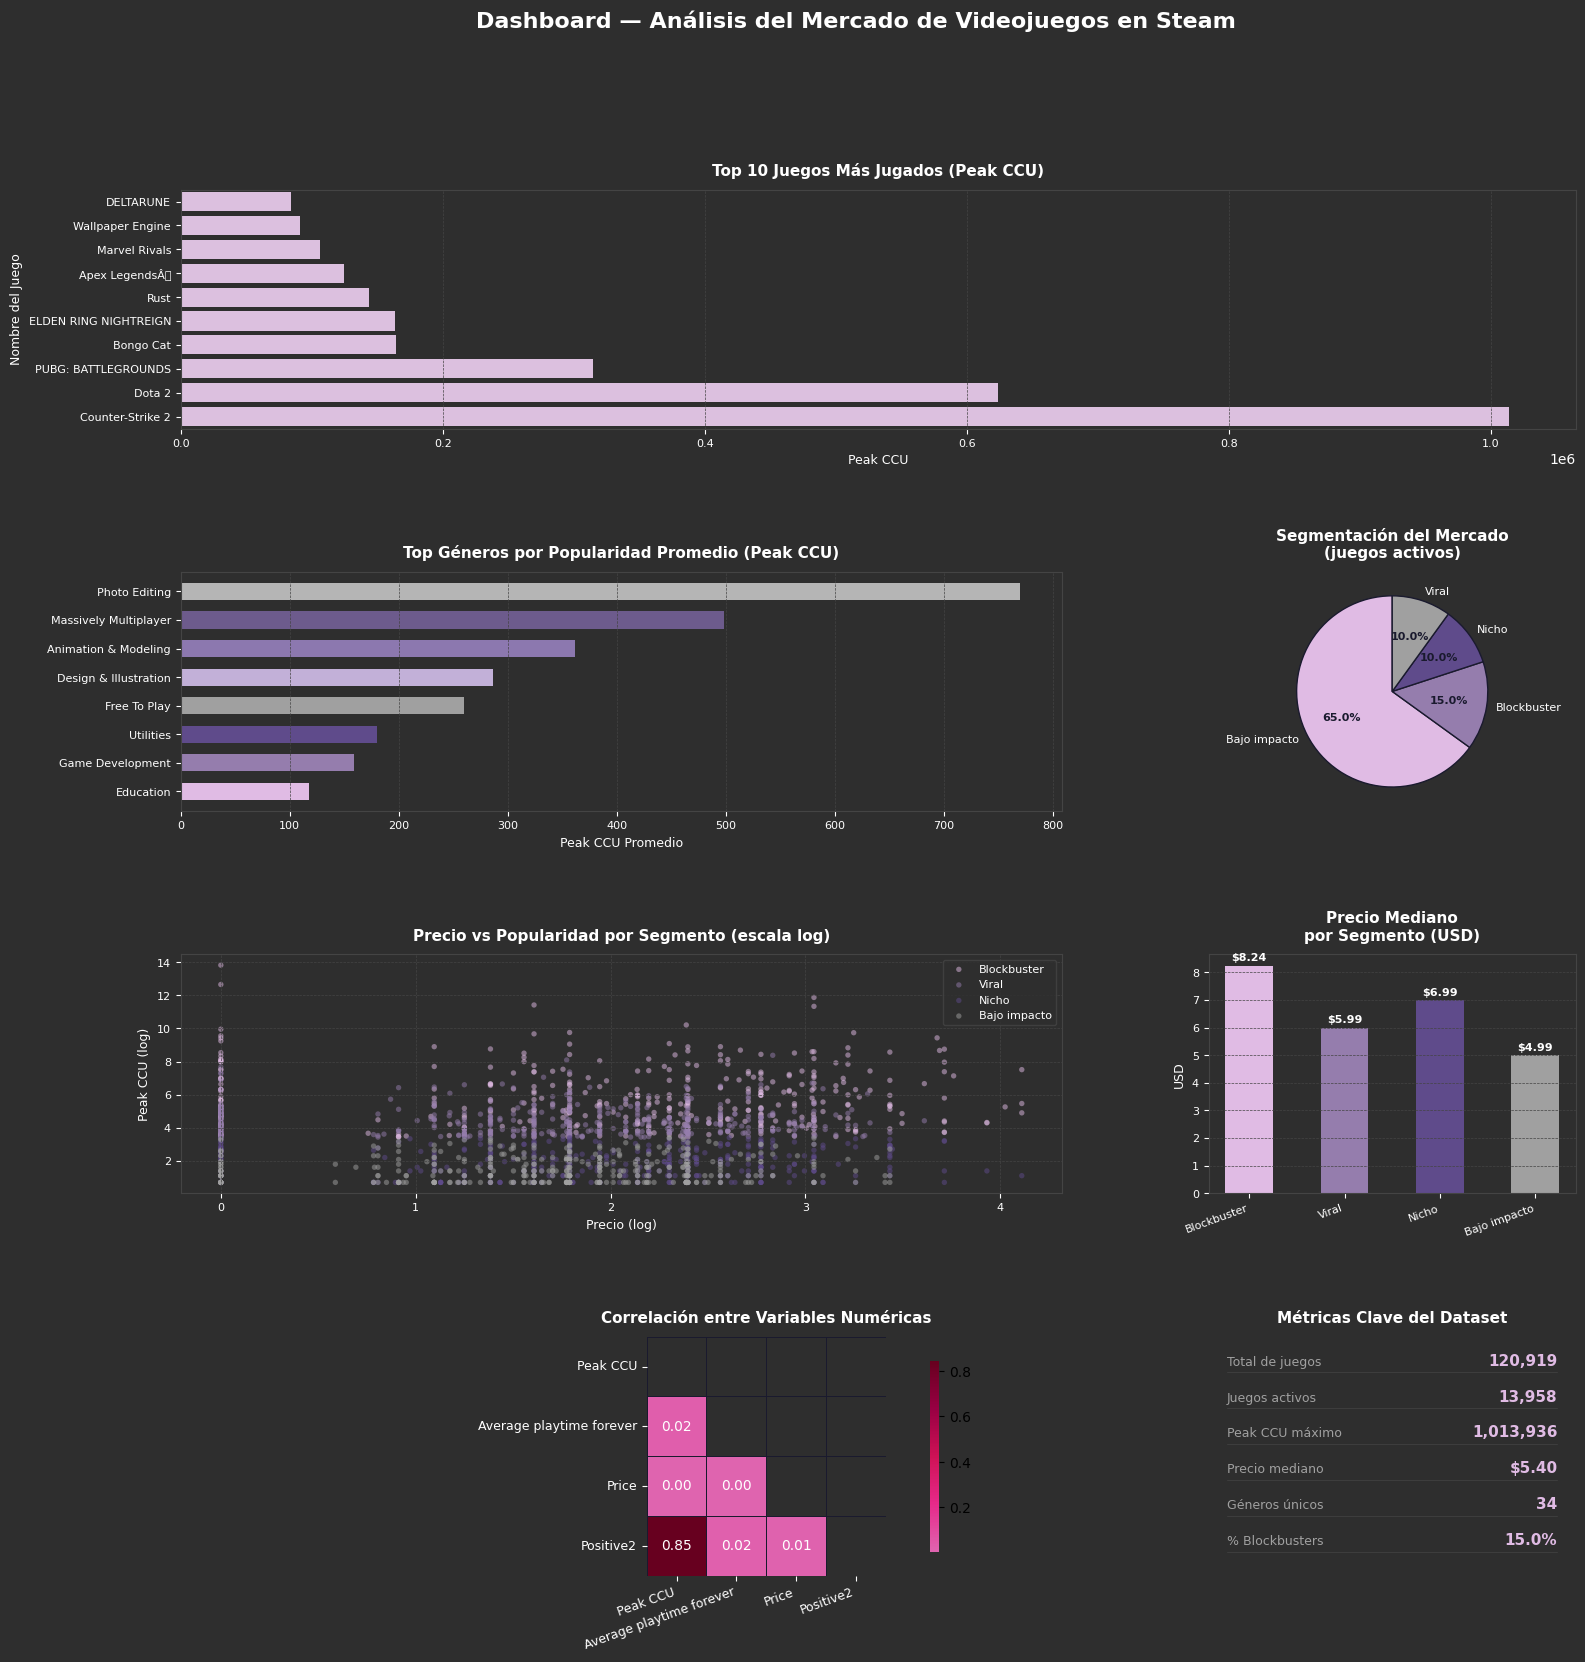

Dashboard guardado como 'dashboard_steam.png'


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# ── CARGA DE DATOS (por si no están en memoria o están vacíos) ───────────────────────────────

# Always attempt to load the dataset if it's not defined or is empty
# This ensures that if a previous attempt failed and left an empty DataFrame, it tries again.
if 'dataset' not in locals() or dataset.empty:
    try:
        # Simplified pd.read_csv to debug loading issue
        dataset = pd.read_csv("/content/cleaned_games_data.csv")
    except FileNotFoundError:
        print("Error: 'cleaned_games_data.csv' not found. Please upload the file or provide the correct path.")
        dataset = pd.DataFrame() # Create an empty DataFrame to avoid NameError later
    except Exception as e:
        print(f"An unexpected error occurred while loading the dataset: {e}")
        dataset = pd.DataFrame()


if 'dataset' in locals() and not dataset.empty: # Only proceed if dataset was loaded successfully
    try:
        dataset_activos
    except NameError:
        if 'Peak CCU' in dataset.columns and 'Average playtime forever' in dataset.columns:
            dataset_activos = dataset[(dataset['Peak CCU'] > 0) & (dataset['Average playtime forever'] > 0)].copy()

            umbral_ccu      = dataset_activos["Peak CCU"].quantile(0.75)
            umbral_playtime = dataset_activos["Average playtime forever"].quantile(0.75)

            dataset_activos["Segmento"] = "Bajo impacto"
            dataset_activos.loc[(dataset_activos["Peak CCU"] > umbral_ccu) &
                                (dataset_activos["Average playtime forever"] > umbral_playtime), "Segmento"] = "Blockbuster"
            dataset_activos.loc[(dataset_activos["Peak CCU"] > umbral_ccu) &
                                (dataset_activos["Average playtime forever"] <= umbral_playtime), "Segmento"] = "Viral"
            dataset_activos.loc[(dataset_activos["Peak CCU"] <= umbral_ccu) &
                                (dataset_activos["Average playtime forever"] > umbral_playtime), "Segmento"] = "Nicho"

            dataset_activos["Genero_Principal"] = dataset_activos["Genre"].str.split(",").str[0].str.strip()
        else:
            print("Advertencia: 'Peak CCU' o 'Average playtime forever' no están en el DataFrame 'dataset'. No se pudo crear 'dataset_activos'.")
            dataset_activos = pd.DataFrame() # Ensure dataset_activos is defined as empty


# ── PREPARACIÓN DE DATOS (only if dataset_activos is available) ──────────────────────────────────────────────────────
if 'dataset_activos' in locals() and not dataset_activos.empty:
    # 1. Top 8 géneros por Peak CCU promedio (expandiendo géneros múltiples)
    dataset_genres_expanded = dataset.copy()
    dataset_genres_expanded['Genre'] = dataset_genres_expanded['Genre'].str.split(',')
    dataset_genres_expanded = dataset_genres_expanded.explode('Genre')
    dataset_genres_expanded['Genre'] = dataset_genres_expanded['Genre'].str.strip()
    genre_peak_ccu = (dataset_genres_expanded
                    .groupby('Genre')['Peak CCU']
                    .mean()
                    .sort_values(ascending=False)
                    .head(8))

    # 2. Conteo de segmentos
    seg_counts = dataset_activos['Segmento'].value_counts()

    # 3. Precio mediano por segmento
    seg_price = dataset_activos.groupby('Segmento')['Price'].median()

    # 4. Matriz de correlación
    cols_corr = ['Peak CCU', 'Average playtime forever', 'Price', 'Positive2']
    corr_matrix = dataset[cols_corr].corr()

    # 5. Data for Top 10 Most Played Games
    top_10_played_games = dataset_activos.sort_values(by='Peak CCU', ascending=False).head(10)

    # ── FIGURA PRINCIPAL ──────────────────────────────────────────────────────────

    fig = plt.figure(figsize=(18, 18))
    fig.patch.set_facecolor('#2E2E2E') # Dark background - changed to lighter gray

    gs = gridspec.GridSpec(4, 3, figure=fig, hspace=0.6, wspace=0.4) # Increased rows from 3 to 4, adjusted hspace

    # Define new color palette
    TEXT_WHITE = '#FFFFFF'
    GRID_LIGHT_GREY = '#444444'
    VIOLET_LIGHT = '#E0BBE4'
    VIOLET_MEDIUM = '#957DAD'
    VIOLET_DARK = '#5F4B8B'
    GREY_ACCENT = '#A0A0A0'

    COLORS = [VIOLET_LIGHT, VIOLET_MEDIUM, VIOLET_DARK, GREY_ACCENT, '#C2B0D8', '#8C78AF', '#6D5B8C', '#B5B5B5']
    TEXT_COLOR = TEXT_WHITE
    GRID_COLOR = GRID_LIGHT_GREY

    # ── PANEL 7 (fila 0, col 0-2): Top 10 Most Played Games ───────────────
    ax7 = fig.add_subplot(gs[0, :]) # Moved to the first row
    sns.barplot(x='Peak CCU', y='Name', data=top_10_played_games.iloc[::-1], color=VIOLET_LIGHT, ax=ax7) # Reverse for highest at top
    ax7.set_facecolor('#2E2E2E')
    ax7.set_title('Top 10 Juegos Más Jugados (Peak CCU)', color=TEXT_COLOR, fontsize=11, fontweight='bold', pad=10)
    ax7.set_xlabel('Peak CCU', color=TEXT_COLOR, fontsize=9)
    ax7.set_ylabel('Nombre del Juego', color=TEXT_COLOR, fontsize=9)
    ax7.tick_params(colors=TEXT_COLOR, labelsize=8)
    for spine in ax7.spines.values():
        spine.set_edgecolor(GRID_COLOR)
    ax7.grid(axis='x', color=GRID_COLOR, linestyle='--', linewidth=0.5)

    # ── PANEL 1 (fila 1, col 0-1): Top géneros por Peak CCU promedio ──────────────
    ax1 = fig.add_subplot(gs[1, :2]) # Shifted down
    bars = ax1.barh(genre_peak_ccu.index[::-1],
                    genre_peak_ccu.values[::-1],
                    color=COLORS[:len(genre_peak_ccu)],
                    edgecolor='none', height=0.6)
    ax1.set_facecolor('#2E2E2E') # Updated subplot background
    ax1.set_title('Top Géneros por Popularidad Promedio (Peak CCU)',
                  color=TEXT_COLOR, fontsize=11, fontweight='bold', pad=10)
    ax1.set_xlabel('Peak CCU Promedio', color=TEXT_COLOR, fontsize=9)
    ax1.tick_params(colors=TEXT_COLOR, labelsize=8)
    ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    for spine in ax1.spines.values():
        spine.set_edgecolor(GRID_COLOR)
    ax1.grid(axis='x', color=GRID_COLOR, linestyle='--', linewidth=0.5)

    # ── PANEL 2 (fila 1, col 2): Distribución de segmentos (torta) ───────────────
    ax2 = fig.add_subplot(gs[1, 2]) # Shifted down
    wedge_colors = [VIOLET_LIGHT, VIOLET_MEDIUM, VIOLET_DARK, GREY_ACCENT]
    wedges, texts, autotexts = ax2.pie(
        seg_counts.values,
        labels=seg_counts.index,
        autopct='%1.1f%%',
        colors=wedge_colors,
        startangle=90,
        textprops={'color': TEXT_COLOR, 'fontsize': 8},
        wedgeprops={'linewidth': 1, 'edgecolor': '#1a1a2e'}
    )
    for at in autotexts:
        at.set_color('#1a1a2e') # Keep dark color for labels on light pie segments
        at.set_fontweight('bold')
        at.set_fontsize(8)
    ax2.set_facecolor('#2E2E2E') # Updated subplot background
    ax2.set_title('Segmentación del Mercado\n(juegos activos)',
                  color=TEXT_COLOR, fontsize=11, fontweight='bold', pad=10)

    # ── PANEL 3 (fila 2, col 0-1): Scatter Peak CCU vs Playtime por segmento ─────
    ax3 = fig.add_subplot(gs[2, :2]) # Shifted down
    seg_colors = {'Blockbuster': VIOLET_LIGHT, 'Viral': VIOLET_MEDIUM,
                  'Nicho': VIOLET_DARK, 'Bajo impacto': GREY_ACCENT}
    for seg, color in seg_colors.items():
        subset = dataset_activos[dataset_activos['Segmento'] == seg].sample(
            min(400, len(dataset_activos[dataset_activos['Segmento'] == seg])),
            random_state=42)
        ax3.scatter(np.log1p(subset['Price']),
                    np.log1p(subset['Peak CCU']),
                    c=color, label=seg, alpha=0.5, s=15, edgecolors='none')
    ax3.set_facecolor('#2E2E2E') # Updated subplot background
    ax3.set_title('Precio vs Popularidad por Segmento (escala log)',
                  color=TEXT_COLOR, fontsize=11, fontweight='bold', pad=10)
    ax3.set_xlabel('Precio (log)', color=TEXT_COLOR, fontsize=9)
    ax3.set_ylabel('Peak CCU (log)', color=TEXT_COLOR, fontsize=9)
    ax3.tick_params(colors=TEXT_COLOR, labelsize=8)
    ax3.grid(color=GRID_COLOR, linestyle='--', linewidth=0.5)
    for spine in ax3.spines.values():
        spine.set_edgecolor(GRID_COLOR)
    ax3.legend(fontsize=8, facecolor='#2E2E2E', labelcolor=TEXT_COLOR, edgecolor=GRID_COLOR) # Updated legend facecolor

    # ── PANEL 4 (fila 2, col 2): Precio mediano por segmento ─────────────────────
    ax4 = fig.add_subplot(gs[2, 2]) # Shifted down
    seg_order = ['Blockbuster', 'Viral', 'Nicho', 'Bajo impacto']
    seg_price_ordered = seg_price.reindex(seg_order)
    bar_colors = [seg_colors[s] for s in seg_order]
    ax4.bar(seg_order, seg_price_ordered.values,
            color=bar_colors, edgecolor='none', width=0.5)
    ax4.set_facecolor('#2E2E2E') # Updated subplot background
    ax4.set_title('Precio Mediano\npor Segmento (USD)',
                  color=TEXT_COLOR, fontsize=11, fontweight='bold', pad=10)
    ax4.set_ylabel('USD', color=TEXT_COLOR, fontsize=9)
    ax4.tick_params(colors=TEXT_COLOR, labelsize=8)
    ax4.set_xticklabels(seg_order, rotation=20, ha='right')
    for spine in ax4.spines.values():
        spine.set_edgecolor(GRID_COLOR)
    ax4.grid(axis='y', color=GRID_COLOR, linestyle='--', linewidth=0.5)
    for bar, val in zip(ax4.patches, seg_price_ordered.values):
        ax4.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.1,
                 f'${val:.2f}', ha='center', va='bottom',
                 color=TEXT_COLOR, fontsize=8, fontweight='bold')

    # ── PANEL 5 (fila 3, col 0-1): Mapa de calor de correlaciones ────────────────
    ax5 = fig.add_subplot(gs[3, :2]) # Shifted down
    mask = np.zeros_like(corr_matrix, dtype=bool)
    mask[np.triu_indices_from(mask)] = True
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', mask=mask,
                cmap='PuRd', center=0, square=True, # Changed cmap to PuRd for violet-red gradient
                linewidths=0.5, linecolor='#1a1a2e',
                annot_kws={'size': 10, 'color': 'white'},
                ax=ax5,
                cbar_kws={'shrink': 0.8})
    ax5.set_facecolor('#2E2E2E') # Updated subplot background
    ax5.set_title('Correlación entre Variables Numéricas',
                  color=TEXT_COLOR, fontsize=11, fontweight='bold', pad=10)
    ax5.tick_params(colors=TEXT_COLOR, labelsize=9)
    ax5.set_xticklabels(ax5.get_xticklabels(), rotation=20, ha='right')
    ax5.set_yticklabels(ax5.get_yticklabels(), rotation=0)

    # ── PANEL 6 (fila 3, col 2): KPIs / tarjetas de métricas clave ───────────────
    ax6 = fig.add_subplot(gs[3, 2]) # Shifted down
    ax6.set_facecolor('#2E2E2E') # Updated subplot background
    ax6.axis('off')
    ax6.set_title('Métricas Clave del Dataset',
                  color=TEXT_COLOR, fontsize=11, fontweight='bold', pad=10)

    kpis = [
        ('Total de juegos',  f'{len(dataset):,}'),
        ('Juegos activos',   f'{len(dataset_activos):,}'),
        ('Peak CCU máximo',  f'{dataset["Peak CCU"].max():,}'),
        ('Precio mediano',   f'${dataset_activos["Price"].median():.2f}'),
        ('Géneros únicos',   f'{dataset["Genre"].dropna().str.split(",").explode().str.strip().nunique()}'),
        ('% Blockbusters',   f'{(seg_counts.get("Blockbuster", 0) / seg_counts.sum() * 100):.1f}%'),
    ]

    for i, (label, value) in enumerate(kpis):
        y = 0.88 - i * 0.15
        ax6.text(0.05, y, label, transform=ax6.transAxes,
                 color=GREY_ACCENT, fontsize=9)
        ax6.text(0.95, y, value, transform=ax6.transAxes,
                 color=VIOLET_LIGHT, fontsize=11, fontweight='bold', ha='right')
        ax6.axhline(y=y - 0.03, xmin=0.05, xmax=0.95,
                    color=GRID_COLOR, linewidth=0.5)

    # ── TÍTULO GENERAL ────────────────────────────────────────────────────────────
    fig.suptitle('Dashboard — Análisis del Mercado de Videojuegos en Steam',
                 fontsize=16, fontweight='bold', color=TEXT_COLOR, y=0.98)

    plt.savefig('dashboard_steam.png', dpi=150, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    plt.show()
    print("Dashboard guardado como 'dashboard_steam.png'")
else:
    print("Skipping dashboard generation because dataset could not be loaded.")

## Resumen del Dashboard

Este dashboard ofrece una visión integral del mercado de videojuegos en Steam, combinando diversas métricas clave:

*   **Top 10 Juegos Más Jugados (Peak CCU):** Muestra los títulos que alcanzan los picos más altos de jugadores simultáneos, indicando las experiencias más populares.
*   **Top Géneros por Popularidad Promedio (Peak CCU):** Destaca los géneros que, en promedio, atraen a más jugadores, como 'Massively Multiplayer' y 'Animation & Modeling'.
*   **Segmentación del Mercado:** Divide los juegos activos en segmentos como 'Blockbuster', 'Viral', 'Nicho' y 'Bajo Impacto', ayudando a entender qué tipo de éxito es más común.
*   **Precio vs Popularidad por Segmento:** Explora la relación entre el precio del juego y su popularidad dentro de cada segmento, utilizando una escala logarítmica para visualizar tendencias.
*   **Precio Mediano por Segmento:** Compara los precios medianos de los juegos en cada segmento, sugiriendo estrategias de monetización.
*   **Correlación entre Variables Numéricas:** Un mapa de calor que visualiza la relación entre `Peak CCU`, `Average playtime forever`, `Price` y `Positive2` (reseñas positivas), mostrando por ejemplo una fuerte correlación entre `Peak CCU` y `Positive2`.
*   **Métricas Clave del Dataset:** Presenta KPIs como el número total de juegos, juegos activos, Peak CCU máximo, precio mediano general, géneros únicos y el porcentaje de Blockbusters, ofreciendo una instantánea del estado del mercado.

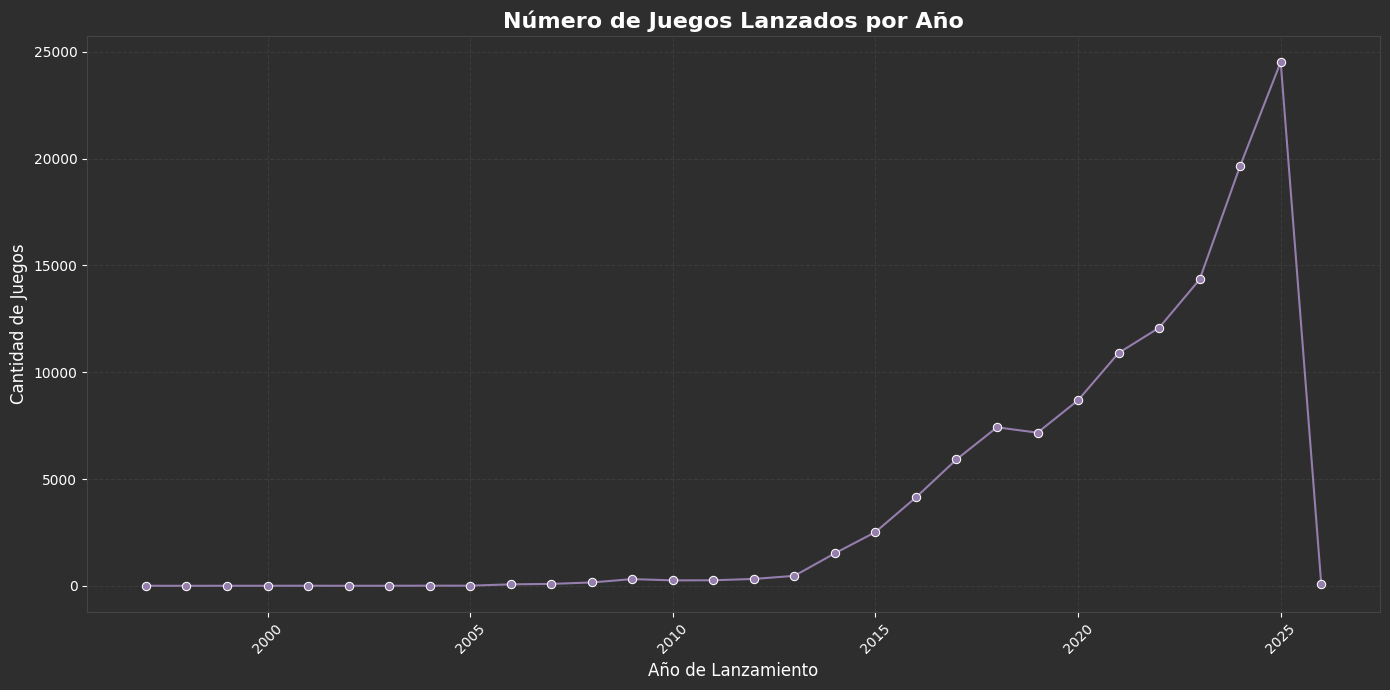

In [ ]:
if 'dataset' in locals() and not dataset.empty:
    # Define new color palette consistent with the dashboard
    TEXT_WHITE = '#FFFFFF'
    GRID_LIGHT_GREY = '#444444'
    VIOLET_LIGHT = '#E0BBE4'
    VIOLET_MEDIUM = '#957DAD'
    VIOLET_DARK = '#5F4B8B'
    GREY_ACCENT = '#A0A0A0'

    TEXT_COLOR = TEXT_WHITE
    GRID_COLOR = GRID_LIGHT_GREY
    BG_COLOR = '#2E2E2E'

    # Convert 'Release date' to datetime objects and extract the year
    dataset['Release_Year'] = pd.to_datetime(dataset['Release date'], errors='coerce').dt.year

    # Count the number of games released each year
    games_per_year = dataset['Release_Year'].value_counts().sort_index()

    # Filter out potential future dates or erroneous years if any (e.g., year 0, or too far in the future)
    current_year = pd.to_datetime('now').year
    games_per_year = games_per_year[(games_per_year.index > 1990) & (games_per_year.index <= current_year + 5)]

    # Plotting the time series
    fig, ax = plt.subplots(figsize=(14, 7))
    fig.patch.set_facecolor(BG_COLOR)
    ax.set_facecolor(BG_COLOR)

    sns.lineplot(x=games_per_year.index, y=games_per_year.values, marker='o', color=VIOLET_MEDIUM, ax=ax)

    ax.set_title('Número de Juegos Lanzados por Año', fontsize=16, fontweight='bold', color=TEXT_COLOR)
    ax.set_xlabel('Año de Lanzamiento', fontsize=12, color=TEXT_COLOR)
    ax.set_ylabel('Cantidad de Juegos', fontsize=12, color=TEXT_COLOR)
    ax.grid(True, linestyle='--', alpha=0.6, color=GRID_COLOR)
    ax.tick_params(axis='x', colors=TEXT_COLOR, labelsize=10, rotation=45)
    ax.tick_params(axis='y', colors=TEXT_COLOR, labelsize=10)

    # Set spine colors
    for spine in ax.spines.values():
        spine.set_edgecolor(GRID_COLOR)

    plt.tight_layout()
    plt.show()
else:
    print("El DataFrame 'dataset' no está disponible o está vacío. No se puede generar el gráfico de series de tiempo.")

## Resumen del Gráfico de Series de Tiempo

Este gráfico de series de tiempo ilustra la evolución del número de juegos lanzados por año. Se observa una tendencia clara y creciente en la cantidad de títulos que se lanzan en Steam a lo largo del tiempo, con un aumento significativo en los últimos años. Esto sugiere un mercado en constante expansión y cada vez más competitivo en términos de lanzamientos.

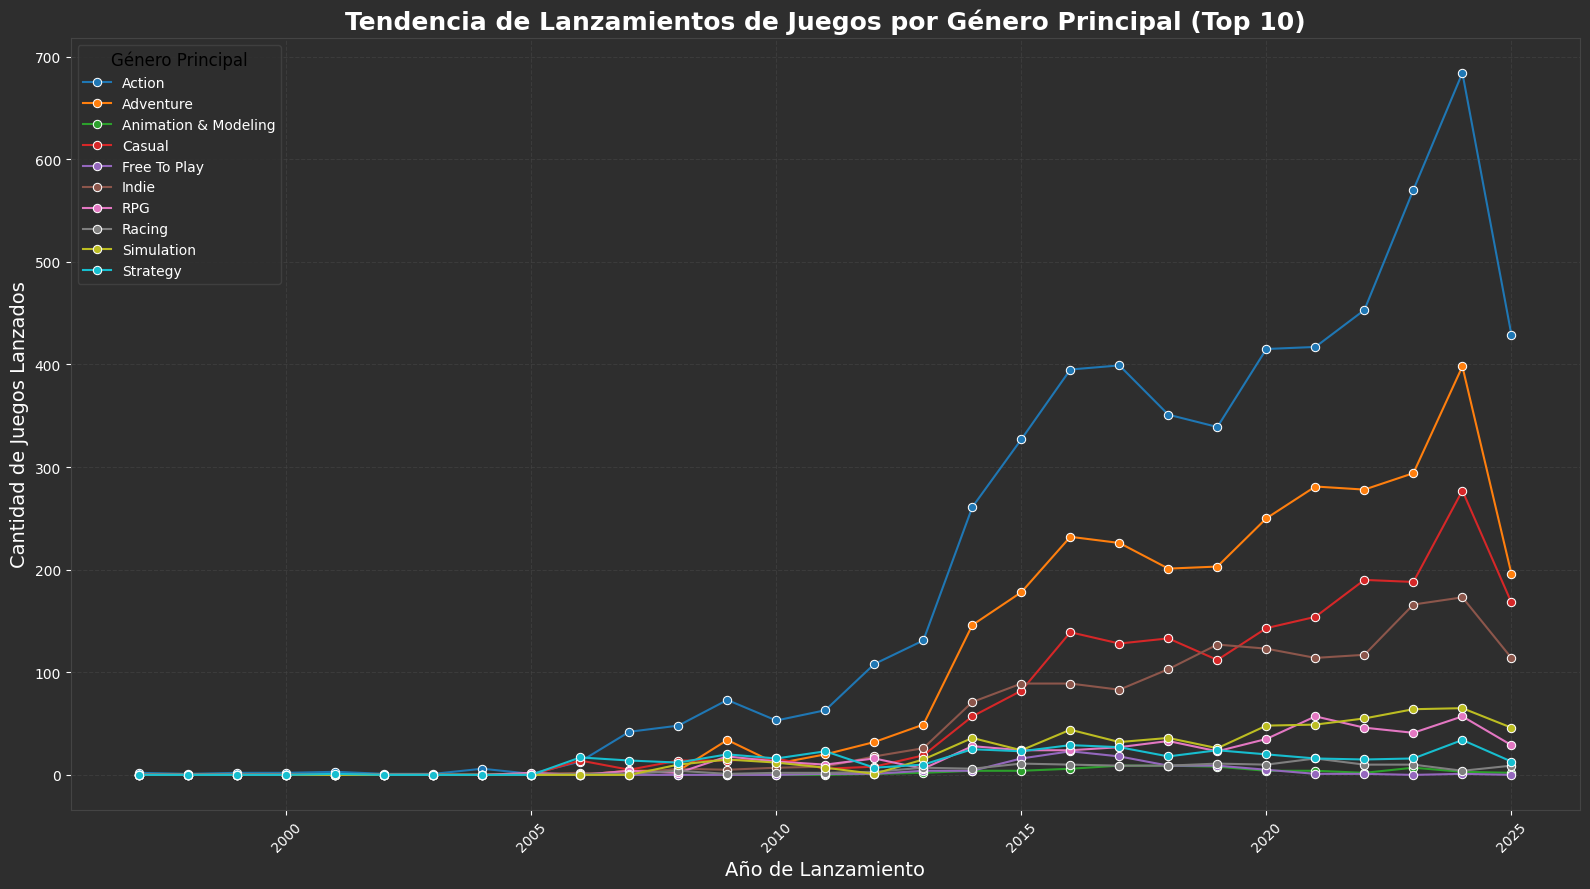

In [ ]:
if 'dataset_activos' in locals() and not dataset_activos.empty:
    # Ensure Release_Year is available in dataset_activos
    if 'Release_Year' not in dataset_activos.columns:
        dataset_activos['Release_Year'] = pd.to_datetime(dataset_activos['Release date'], errors='coerce').dt.year

    # Ensure Genero_Principal is available in dataset_activos
    if 'Genero_Principal' not in dataset_activos.columns:
        dataset_activos['Genero_Principal'] = dataset_activos['Genre'].str.split(',').str[0].str.strip()

    # Get the top N genres (e.g., Top 10) based on overall game count in dataset_activos
    top_genres = dataset_activos['Genero_Principal'].value_counts().head(10).index.tolist()

    # Filter the dataset for only these top genres
    df_top_genres = dataset_activos[dataset_activos['Genero_Principal'].isin(top_genres)].copy()

    # Count games per year and per genre
    releases_by_genre_year = df_top_genres.groupby(['Release_Year', 'Genero_Principal']).size().unstack(fill_value=0)

    # Filter out potential future dates or erroneous years for the plot
    current_year = pd.to_datetime('now').year
    releases_by_genre_year = releases_by_genre_year[(releases_by_genre_year.index > 1990) & (releases_by_genre_year.index <= current_year + 5)]

    # Reshape for seaborn lineplot
    df_plot_genres = releases_by_genre_year.stack().reset_index(name='Cantidad_Juegos')
    df_plot_genres.rename(columns={0: 'Cantidad_Juegos'}, inplace=True)

    # Define colors for consistency
    TEXT_WHITE = '#FFFFFF'
    GRID_LIGHT_GREY = '#444444'
    BG_COLOR = '#2E2E2E'

    # Use a color palette that stands out on the dark background for genres
    genre_palette = sns.color_palette('tab10', n_colors=len(top_genres))

    fig, ax = plt.subplots(figsize=(16, 9))
    fig.patch.set_facecolor(BG_COLOR)
    ax.set_facecolor(BG_COLOR)

    sns.lineplot(
        data=df_plot_genres,
        x='Release_Year',
        y='Cantidad_Juegos',
        hue='Genero_Principal',
        marker='o',
        ax=ax,
        palette=genre_palette
    )

    ax.set_title('Tendencia de Lanzamientos de Juegos por Género Principal (Top 10)', fontsize=18, fontweight='bold', color=TEXT_WHITE)
    ax.set_xlabel('Año de Lanzamiento', fontsize=14, color=TEXT_WHITE)
    ax.set_ylabel('Cantidad de Juegos Lanzados', fontsize=14, color=TEXT_WHITE)
    ax.grid(True, linestyle='--', alpha=0.6, color=GRID_LIGHT_GREY)
    ax.tick_params(axis='x', colors=TEXT_WHITE, labelsize=10, rotation=45)
    ax.tick_params(axis='y', colors=TEXT_WHITE, labelsize=10)
    ax.legend(title='Género Principal', title_fontsize='12', fontsize='10', labelcolor=TEXT_WHITE, facecolor=BG_COLOR, edgecolor=GRID_LIGHT_GREY)

    # Set spine colors
    for spine in ax.spines.values():
        spine.set_edgecolor(GRID_LIGHT_GREY)

    plt.tight_layout()
    plt.show()
else:
    print("El DataFrame 'dataset_activos' no está disponible o está vacío. No se puede generar el gráfico de tendencias de lanzamientos por género.")

## Resumen del Gráfico de Tendencias de Lanzamientos por Género

Este gráfico de líneas muestra cómo ha evolucionado la cantidad de juegos lanzados por año para los 10 géneros principales. Podemos observar varias tendencias clave:

*   **Crecimiento General:** La mayoría de los géneros muestran un incremento sostenido en el número de lanzamientos a lo largo del tiempo, reflejando el crecimiento general del mercado de videojuegos.
*   **Dominio de Géneros:** Géneros como 'Action' y 'Adventure' consistentemente tienen un alto volumen de lanzamientos, indicando su popularidad continua entre desarrolladores y jugadores.
*   **Picos de Crecimiento:** Algunos géneros experimentan periodos de crecimiento más acelerado, lo que podría indicar modas o tendencias dentro de la industria en ciertos años.
*   **Saturación:** La concentración de líneas en la parte superior del gráfico en años recientes sugiere una mayor saturación en ciertos géneros, haciendo más difícil para los nuevos títulos destacar.

##Conclusión Final — Análisis del Mercado de Videojuegos en Steam
El análisis de 120.919 títulos de Steam permitió identificar patrones claros de éxito y oportunidad para orientar decisiones estratégicas de desarrollo.

El mercado está saturado, pero el éxito es predecible. Más del 75% de los juegos no registra jugadores ni tiempo de juego. Sin embargo, el 15% que sí lo logra comparte características concretas: géneros como Strategy y RPG concentran la mayor proporción de Blockbusters, mientras que Casual y Action son los más saturados y difíciles de penetrar.

El precio no garantiza éxito, pero sí define el público. Los géneros Simulation y RPG sostienen precios de entre $8 y $10 USD con audiencias de mayor poder adquisitivo. El modelo Free to Play, contra lo esperado, no asegura mayor adopción masiva.

La localización es un motor de crecimiento. Existe una correlación directa entre cantidad de idiomas y popularidad, con un punto óptimo en 9 idiomas (inglés, alemán, francés, chino, japonés, coreano, ruso, español y portugués). Más de 12 idiomas muestra retornos decrecientes.

###Recomendacion:
Invertir en un título de Simulación con elementos de RPG. Es el género con mayor Índice de Oportunidad (alta demanda, baja competencia de calidad), audiencias dispuestas a pagar más y tiempos de retención que habilitan monetización a largo plazo mediante DLCs. Complementado con localización en los 9 mercados clave, representa la apuesta con mejor relación riesgo-retorno dentro del ecosistema Steam.